# Controlled historical-context ablation — mean-reverting synthetic market

K0, K1, K5 and K60 expose zero, one, five or sixty historical observations to the
**same** Vanilla MLP diffusion encoder. Every input still has shape `[batch, 60, 12]`.
Earlier **standardized** observations are zeroed (the training mean), without changing
raw histories, targets, scaler, dates, architecture or parameter count.

The common predeclared budget is **15 epochs**, with best-validation-loss selection.
Only that budget differs from `synthetic_mean_reverting.yaml`. This is a diagnostic
budget, not a claim of optimality. The historical 50-epoch K60 run is excluded.

**Hypotheses, not outcomes:** K0 may show little direct lag dependence; K1 may help
for a one-lag process; K5 tests modest additional history; K60 may introduce optimization
difficulty or overfitting. Rank forecasting quality using CRPS, Energy Score and
predictive log-mean MSE, not lag slope alone. Validation selected the checkpoints:
comparisons and block intervals are exploratory development evidence, not independent
held-out or selection-adjusted significance. The test partition stays untouched.

Run All performs **only two epochs each for K1 and K60**, followed by first-64-date
inference (256 scenarios). All four 15-epoch commands are Markdown at the end.

## Setup

Enable Kaggle Internet; a GPU is useful for inference. This uses the established
`feature/synthetic-market` synchronization cell. No existing artifacts are restored
or modified automatically.

In [2]:
import os
import sys

REPO_PATH = "/kaggle/working/diffusion-portfolio"
USERNAME = "Amir-Entezari"
REPO = "diffusion-portfolio"
BRANCH = "feature/synthetic-market"

repo_url = f"https://github.com/{USERNAME}/{REPO}.git"

# Clone the specified branch if the repository doesn't exist.
if not os.path.exists(os.path.join(REPO_PATH, ".git")):
    !git clone --branch {BRANCH} --single-branch {repo_url} {REPO_PATH}

else:
    # Fetch latest changes from the specified branch.
    !git -C {REPO_PATH} fetch origin {BRANCH}

    # Switch to the branch and force-sync with remote.
    !git -C {REPO_PATH} checkout -B {BRANCH} FETCH_HEAD
    !git -C {REPO_PATH} reset --hard FETCH_HEAD

os.chdir(REPO_PATH)

SRC_PATH = os.path.join(REPO_PATH, "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

# Verify the active branch and latest commit.
!git branch --show-current
!git log -1 --oneline

print(f"Repository synced with origin/{BRANCH}.")

Cloning into '/kaggle/working/diffusion-portfolio'...
remote: Enumerating objects: 1472, done.
remote: Counting objects: 100% (246/246), done.
remote: Compressing objects: 100% (138/138), done.
remote: Total 1472 (delta 146), reused 178 (delta 99), pack-reused 1226 (from 1)
Receiving objects: 100% (1472/1472), 1.56 MiB | 7.92 MiB/s, done.
Resolving deltas: 100% (809/809), done.
feature/synthetic-market
e20cfb5 (HEAD -> feature/synthetic-market, origin/feature/synthetic-market) Add controlled synthetic history-context ablation
Repository synced with origin/feature/synthetic-market.


In [3]:
!pip install -q -e '.[dev]'
assert _exit_code == 0, "Dependency installation failed."

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 2.8 MB/s eta 0:00:00
  Building editable for diffusion-portfolio (pyproject.toml) ... done


## Focused regression tests

Tests use small CPU fixtures; no full research training or held-out scoring.

In [4]:
!pytest -q tests/unit/test_history_ablation.py tests/unit/test_synthetic_diffusion_comparison.py tests/unit/test_diffusion_training.py
assert _exit_code == 0, "Context-ablation regression tests failed."

........................................................................ [ 61%]
.............................................                            [100%]
=============================== warnings summary ===============================
tests/unit/test_history_ablation.py::test_notebook_loss_plots_execute_on_partial_checkpoint_histories
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
    prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))

tests/unit/test_history_ablation.py::test_notebook_loss_plots_execute_on_partial_checkpoint_histories
tests/unit/test_history_ablation.py::test_notebook_loss_plots_execute_on_partial_checkpoint_histories
tests/unit/test_history_ablation.py::test_notebook_loss_plots_execute_on_partial_checkpoint_histories
tests/unit/test_history_ablation.py::test_notebook_loss_plots_execute_on_partial_checkpoint_histories
tests/unit/test_his

## Two-epoch execution pilot — K1

Each run records its immutable mask and full 15-epoch contract before training.
`--stop-after-epoch 2` is an absolute boundary. A K1 directory cannot resume as
K5, K60 or an unspecified policy. `--resume` restores the existing checkpoint/RNG.

In [5]:
!PYTHONUNBUFFERED=1 python -u scripts/train_diffusion.py \
    --config configs/ablations/synthetic_ar1_context.yaml --history-keep-last 1 \
    --output-dir /kaggle/working/synthetic_context/k1 --device auto --resume --stop-after-epoch 2
assert _exit_code == 0, "K1 pilot training failed."

Device: cuda Encoder: mlp
Prediction: v_prediction Parameters: 1044417
Epoch 001/015 | train=0.987016 | val=0.946461 | elapsed=3.2s
Epoch 002/015 | train=0.926752 | val=0.921150 | elapsed=0.8s
Training chunk complete. Resume checkpoint: /kaggle/working/synthetic_context/k1/last.pt


,epoch,train_loss,val_loss
0,1,0.987016,0.946461
1,2,0.926752,0.921150


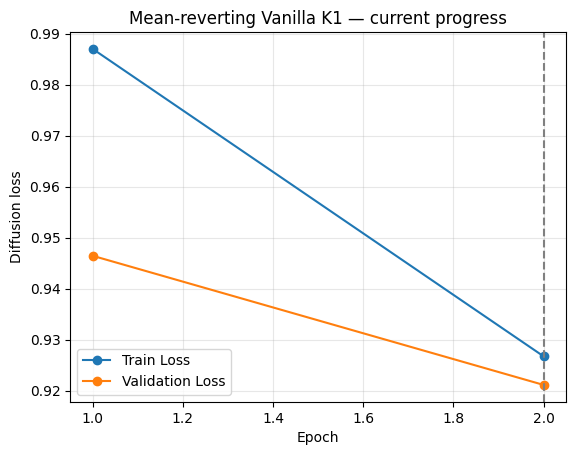

In [6]:
from pathlib import Path
import pandas as pd
import torch
import matplotlib.pyplot as plt

K1_DIR = Path("/kaggle/working/synthetic_context/k1")
history = pd.DataFrame(torch.load(K1_DIR / "last.pt", map_location="cpu", weights_only=False)["history"])
display(history)
ax = history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", title="Mean-reverting Vanilla K1 — current progress")
ax.set(xlabel="Epoch", ylabel="Diffusion loss")
ax.legend(["Train Loss", "Validation Loss"])
ax.axvline(history.loc[history.val_loss.idxmin(), "epoch"], color="gray", linestyle="--", label="Best validation epoch")
ax.grid(alpha=.3)
plt.show()

## Two-epoch execution pilot — K60

Same configuration and initialization seed, separate checkpoint directory.

In [7]:
!PYTHONUNBUFFERED=1 python -u scripts/train_diffusion.py \
    --config configs/ablations/synthetic_ar1_context.yaml --history-keep-last 60 \
    --output-dir /kaggle/working/synthetic_context/k60 --device auto --resume --stop-after-epoch 2
assert _exit_code == 0, "K60 pilot training failed."

Device: cuda Encoder: mlp
Prediction: v_prediction Parameters: 1044417
Epoch 001/015 | train=1.005343 | val=0.971929 | elapsed=1.8s
Epoch 002/015 | train=0.959120 | val=0.964638 | elapsed=0.8s
Training chunk complete. Resume checkpoint: /kaggle/working/synthetic_context/k60/last.pt


,epoch,train_loss,val_loss
0,1,1.005343,0.971929
1,2,0.959120,0.964638


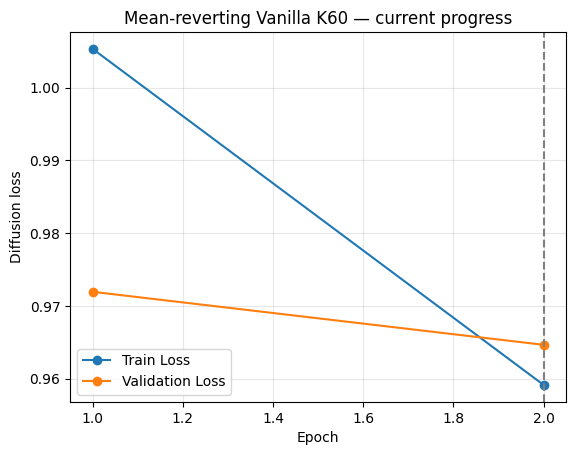

In [8]:
K60_DIR = Path("/kaggle/working/synthetic_context/k60")
history = pd.DataFrame(torch.load(K60_DIR / "last.pt", map_location="cpu", weights_only=False)["history"])
display(history)
ax = history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", title="Mean-reverting Vanilla K60 — current progress")
ax.set(xlabel="Epoch", ylabel="Diffusion loss")
ax.legend(["Train Loss", "Validation Loss"])
ax.axvline(history.loc[history.val_loss.idxmin(), "epoch"], color="gray", linestyle="--")
ax.grid(alpha=.3)
plt.show()

## Verify both checkpoint manifests

Require matching source/scaler, original policy, checkpoint byte bindings, history
and best-checkpoint metadata. Partial runs remain **preliminary**, not completed studies.

In [9]:
from diffusion_portfolio.config import load_config
from diffusion_portfolio.data.preparation import load_standardizer
from diffusion_portfolio.evaluation.forecast_identity import verify_synthetic_checkpoint

for run_dir in (K1_DIR, K60_DIR):
    cfg = load_config(run_dir / "config.yaml")
    best = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=False)
    manifest = verify_synthetic_checkpoint(run_dir, cfg, load_standardizer(run_dir / "standardizer.npz"), best)
    print(run_dir.name, manifest["training_contract"]["history_mask"], manifest["training_run"])

k1 {'keep_last': 1, 'lookback': 60, 'convention': 'zero earlier standardized observations (fitted training mean)'} {'status': 'preliminary', 'completed_epochs': 2, 'configured_epochs': 15, 'checkpoint_epoch': 2, 'checkpoint_val_loss': 0.9211496559778849, 'final_train_loss': 0.9267523545967905, 'final_val_loss': 0.9211496559778849, 'note': 'Training budget completion is not evidence of forecast quality; validation selected this checkpoint.', 'parameter_count': 1044417}
k60 {'keep_last': 60, 'lookback': 60, 'convention': 'zero earlier standardized observations (fitted training mean)'} {'status': 'preliminary', 'completed_epochs': 2, 'configured_epochs': 15, 'checkpoint_epoch': 2, 'checkpoint_val_loss': 0.9646382627487182, 'final_train_loss': 0.9591197505171, 'final_val_loss': 0.9646382627487182, 'note': 'Training budget completion is not evidence of forecast quality; validation selected this checkpoint.', 'parameter_count': 1044417}


## Limited validation inference

The evaluator automatically restores each original mask from the immutable contract;
there is no inference mask override. Only the first 64 validation windows enter the
DataLoader. Destinations must be empty or absent; choose new names for repeated
inference or subsequent completed runs. Batch size/device affect individual draws.

In [10]:
!PYTHONUNBUFFERED=1 python -u scripts/evaluate_diffusion.py \
    --run-dir /kaggle/working/synthetic_context/k1 \
    --split validation --limit 64 --batch-size 16 --device auto \
    --output-dir /kaggle/working/synthetic_context/k1_pilot_inference
assert _exit_code == 0, "K1 limited inference failed."

Sampling: 100%|███████████████████████████████████| 4/4 [00:06<00:00,  1.74s/it]
CRPS: 0.006644599692373968 Energy Score: 0.02782781355916618


In [11]:
!PYTHONUNBUFFERED=1 python -u scripts/evaluate_diffusion.py \
    --run-dir /kaggle/working/synthetic_context/k60 \
    --split validation --limit 64 --batch-size 16 --device auto \
    --output-dir /kaggle/working/synthetic_context/k60_pilot_inference
assert _exit_code == 0, "K60 limited inference failed."

Sampling: 100%|███████████████████████████████████| 4/4 [00:06<00:00,  1.75s/it]
CRPS: 0.00685648882056042 Energy Score: 0.028721760774337822


## Matched observed-only statistical forecasts

Set `BASELINE_DIR` to existing full mean-reverting Stage 4E-1 artifacts with 256 scenarios.
They need not share diffusion's 15-epoch training config, only the exact **data** identity,
assets, dates, raw observations and ensemble size. No mask is applied to statistical models.
If unavailable, leave `None` to generate a small matched baseline. Never substitute KF12
or differently seeded synthetic data. Incompatible archives fail strict comparison.

In [12]:
BASELINE_DIR = None  # Optional: Path("/your/saved/mean_reverting_full_baselines")
if BASELINE_DIR is None:
    BASELINE_DIR = Path("/kaggle/working/synthetic_context/matched_baseline_pilot")
    !PYTHONUNBUFFERED=1 python -u scripts/benchmark_synthetic_forecasts.py --config configs/ablations/synthetic_ar1_context.yaml --models gaussian,ar1,ewma --split validation --n-scenarios 256 --limit 64 --seed 42 --output-dir {BASELINE_DIR}
    assert _exit_code == 0, "Matched statistical benchmark failed."
else:
    BASELINE_DIR = Path(BASELINE_DIR)
    assert (BASELINE_DIR / "report.json").is_file(), "Missing existing baseline report."

gaussian: CRPS=0.00703623 | Energy Score=0.02942767 | mean |ACE|=0.021490
ar1: CRPS=0.00644983 | Energy Score=0.02691680 | mean |ACE|=0.024094
ewma: CRPS=0.00689634 | Energy Score=0.02885714 | mean |ACE|=0.030083


## Paired comparisons against statistical baselines

The existing tool verifies full source alignment and uses the same 64 targets from
longer baseline archives. Negative diffusion-minus-baseline differences favor diffusion.
Block length 20 and 1,000 replications are fixed here; 64-date intervals are exploratory.

In [13]:
!PYTHONUNBUFFERED=1 python -u scripts/compare_synthetic_forecasts.py \
    --baseline-dir {BASELINE_DIR} \
    --diffusion-dir /kaggle/working/synthetic_context/k1_pilot_inference \
    --block-length 20 --n-bootstrap 1000 --bootstrap-seed 42 \
    --output-dir /kaggle/working/synthetic_context/k1_pilot_comparison
assert _exit_code == 0, "K1 paired baseline comparison failed."

baseline       metric  n_dates  diffusion_mean  baseline_mean  mean_difference  relative_improvement  paired_sample_std  ci95_lower  ci95_upper
     ar1         crps       64        0.006645       0.006450         0.000195             -0.030198           0.000780    0.000092    0.000284
     ar1 energy_score       64        0.027828       0.026917         0.000911             -0.033846           0.002914    0.000495    0.001205
    ewma         crps       64        0.006645       0.006896        -0.000252              0.036504           0.001552   -0.000544   -0.000076
    ewma energy_score       64        0.027828       0.028857        -0.001029              0.035670           0.006008   -0.002203   -0.000395
gaussian         crps       64        0.006645       0.007036        -0.000392              0.055659           0.001677   -0.000894   -0.000205
gaussian energy_score       64        0.027828       0.029428        -0.001600              0.054366           0.006452   -0.003517   -0

In [14]:
!PYTHONUNBUFFERED=1 python -u scripts/compare_synthetic_forecasts.py \
    --baseline-dir {BASELINE_DIR} \
    --diffusion-dir /kaggle/working/synthetic_context/k60_pilot_inference \
    --block-length 20 --n-bootstrap 1000 --bootstrap-seed 42 \
    --output-dir /kaggle/working/synthetic_context/k60_pilot_comparison
assert _exit_code == 0, "K60 paired baseline comparison failed."

baseline       metric  n_dates  diffusion_mean  baseline_mean  mean_difference  relative_improvement  paired_sample_std  ci95_lower  ci95_upper
     ar1         crps       64        0.006856       0.006450         0.000407             -0.063050           0.001060    0.000275    0.000539
     ar1 energy_score       64        0.028722       0.026917         0.001805             -0.067057           0.004104    0.001329    0.002351
    ewma         crps       64        0.006856       0.006896        -0.000040              0.005779           0.001149   -0.000319    0.000126
    ewma energy_score       64        0.028722       0.028857        -0.000135              0.004691           0.004414   -0.001198    0.000462
gaussian         crps       64        0.006856       0.007036        -0.000180              0.025545           0.001577   -0.000645   -0.000012
gaussian energy_score       64        0.028722       0.029428        -0.000706              0.023988           0.005985   -0.002419   -0

## Context and conditional-dependence diagnostics

The archive-only diagnostic uses **actual unmasked raw history**, converts with `log1p`,
averages log scenarios and demeans separately per asset before pooling the lag slope.
The true coefficient 0.4 is a reference only. Forecast-ensemble means are noisy estimates,
not exact conditional expectations. Scores use the existing arithmetic-return metrics.

Direct arm comparisons require exactly equal dates, observations, scenario counts,
configuration except mask, and completed budgets. No date intersection is silently taken.
Paired block intervals condition on saved ensembles and omit training, model-selection
and repeated Monte Carlo uncertainty.

In [15]:
!PYTHONUNBUFFERED=1 python -u scripts/diagnose_history_ablation.py \
    --baseline-dir {BASELINE_DIR} \
    --diffusion-dirs K1=/kaggle/working/synthetic_context/k1_pilot_inference K60=/kaggle/working/synthetic_context/k60_pilot_inference \
    --block-length 20 --n-bootstrap 1000 --bootstrap-seed 42 \
    --output-dir /kaggle/working/synthetic_context/pilot_diagnostics
assert _exit_code == 0, "Context diagnostics failed."

   model  pooled_lag_slope  log_mean_mse     crps  energy_score  mean_abs_ace      status  completed_epochs  configured_epochs  checkpoint_epoch  checkpoint_val_loss  final_train_loss  final_val_loss                                                                                                 note  parameter_count
      K1          0.357037      0.000138 0.006645      0.027828      0.032427 preliminary               2.0               15.0               2.0             0.921150          0.926752        0.921150 Training budget completion is not evidence of forecast quality; validation selected this checkpoint.        1044417.0
     K60          0.104482      0.000147 0.006856      0.028722      0.027219 preliminary               2.0               15.0               2.0             0.964638          0.959120        0.964638 Training budget completion is not evidence of forecast quality; validation selected this checkpoint.        1044417.0
     ar1          0.408425      0.000130 0.006

CRPS, Energy Score and predictive log-mean MSE are primary. Lag slope is explanatory, not a ranking criterion. Predictive log means are finite-ensemble estimates. Negative left-minus-right differences favor the left arm. Validation selected checkpoints: exploratory development evidence, not independent held-out or selection-adjusted significance. Moving-block intervals assume approximately stationary paired differences; short pilots and ensemble noise limit interpretation.
Generator AR coefficient (reference only): 0.4


,model,pooled_lag_slope,log_mean_mse,crps,energy_score,mean_abs_ace,status,completed_epochs,configured_epochs,checkpoint_epoch,checkpoint_val_loss,final_train_loss,final_val_loss,note,parameter_count
0,K1,0.357037,0.000138,0.006645,0.027828,0.032427,preliminary,2.0,15.0,2.0,0.921150,0.926752,0.921150,Training budget completion is not evidence of ...,1044417.0
1,K60,0.104482,0.000147,0.006856,0.028722,0.027219,preliminary,2.0,15.0,2.0,0.964638,0.959120,0.964638,Training budget completion is not evidence of ...,1044417.0
2,ar1,0.408425,0.000130,0.006450,0.026917,0.024094,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ewma,0.074355,0.000149,0.006896,0.028857,0.030083,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,gaussian,0.000953,0.000156,0.007036,0.029428,0.021490,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,model,level,coverage,absolute_error
0,K1,0.50,0.459635,0.040365
1,K1,0.80,0.744792,0.055208
2,K1,0.90,0.863281,0.036719
3,K1,0.95,0.927083,0.022917
4,K1,0.99,0.983073,0.006927
5,K60,0.50,0.466146,0.033854
6,K60,0.80,0.753906,0.046094
7,K60,0.90,0.876302,0.023698
8,K60,0.95,0.933594,0.016406
9,K60,0.99,0.973958,0.016042


,left,right,metric,n_dates,left_mean,right_mean,mean_difference,paired_sample_std,ci95_lower,ci95_upper
0,K1,K60,crps,64,0.006645,0.006856,-0.000212,0.001001,-0.000319,-0.000121
1,K1,K60,energy_score,64,0.027828,0.028722,-0.000894,0.004018,-0.001359,-0.000596
2,K1,K60,log_mean_mse,64,0.000138,0.000147,-0.000010,0.000040,-0.000014,-0.000006


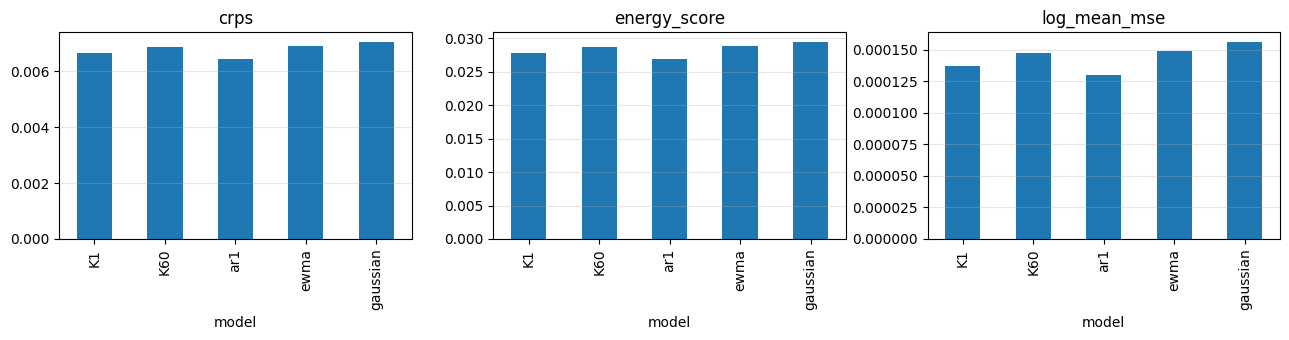

In [16]:
import json

DIAGNOSTICS_DIR = Path("/kaggle/working/synthetic_context/pilot_diagnostics")
report = json.loads((DIAGNOSTICS_DIR / "diagnostics.json").read_text())
print(report["interpretation"])
print("Generator AR coefficient (reference only):", report["generator_ar_coefficient_reference_only"])
summary = pd.read_csv(DIAGNOSTICS_DIR / "summary.csv")
display(summary)
display(pd.read_csv(DIAGNOSTICS_DIR / "calibration.csv"))
display(pd.read_csv(DIAGNOSTICS_DIR / "paired_context.csv"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ("crps", "energy_score", "log_mean_mse")):
    summary.plot.bar(x="model", y=metric, ax=ax, legend=False, title=metric)
    ax.grid(axis="y", alpha=.3)
fig.tight_layout()
plt.show()

## Matched 15-epoch study — manual commands only

These commands are Markdown so Run All never launches all four budgets. K1/K60
continue from their pilots in the **same** directories and unchanged configuration.
K0/K5 start separately. Best checkpoints are selected within each common 15-epoch budget.

```bash
python -u scripts/train_diffusion.py --config configs/ablations/synthetic_ar1_context.yaml --history-keep-last 0 --output-dir /kaggle/working/synthetic_context/k0 --device cuda --resume
python -u scripts/train_diffusion.py --config configs/ablations/synthetic_ar1_context.yaml --history-keep-last 1 --output-dir /kaggle/working/synthetic_context/k1 --device cuda --resume
python -u scripts/train_diffusion.py --config configs/ablations/synthetic_ar1_context.yaml --history-keep-last 5 --output-dir /kaggle/working/synthetic_context/k5 --device cuda --resume
python -u scripts/train_diffusion.py --config configs/ablations/synthetic_ar1_context.yaml --history-keep-last 60 --output-dir /kaggle/working/synthetic_context/k60 --device cuda --resume
```

After **all four** budgets complete, evaluate each using `evaluate_diffusion.py --split validation`
with a distinct new `--output-dir` (omit `--limit` for all 1,500 validation dates).
Reuse compatible full statistical artifacts or generate matched ones with 256 scenarios.
Run `compare_synthetic_forecasts.py` separately for every arm, then run
`diagnose_history_ablation.py --baseline-dir <baseline> --diffusion-dirs K0=<inference> K1=<inference> K5=<inference> K60=<inference> --output-dir <new-diagnostic-directory>`.
Do not mix pilot and completed budgets or the historical 50-epoch run.

Preserve each run's `best.pt`, `last.pt`, `history.csv`, `config.yaml`, `standardizer.npz`,
`data_identity.json`, `experiment.json` and final `summary.json` when present.
Save inference metadata/archives, baseline archives and diagnostic CSV/JSON outputs with
the Kaggle version. There are no automatic uploads or checkpoint repairs.

In [17]:
!python scripts/train_diffusion.py \
  --config configs/ablations/synthetic_ar1_context.yaml \
  --history-keep-last 0 \
  --output-dir /kaggle/working/synthetic_context/k0 \
  --device cuda --resume

Device: cuda Encoder: mlp
Prediction: v_prediction Parameters: 1044417
Epoch 001/015 | train=1.005040 | val=0.974804 | elapsed=1.8s
Epoch 002/015 | train=0.970953 | val=0.973671 | elapsed=0.8s
Epoch 003/015 | train=0.959566 | val=0.964584 | elapsed=0.8s
Epoch 004/015 | train=0.955521 | val=0.965973 | elapsed=0.8s
Epoch 005/015 | train=0.951962 | val=0.960840 | elapsed=0.8s
Epoch 006/015 | train=0.960106 | val=0.959291 | elapsed=0.8s
Epoch 007/015 | train=0.958417 | val=0.959109 | elapsed=0.8s
Epoch 008/015 | train=0.948385 | val=0.962044 | elapsed=0.8s
Epoch 009/015 | train=0.962649 | val=0.958527 | elapsed=0.8s
Epoch 010/015 | train=0.964315 | val=0.958617 | elapsed=0.8s
Epoch 011/015 | train=0.954765 | val=0.958313 | elapsed=0.8s
Epoch 012/015 | train=0.947374 | val=0.959598 | elapsed=0.8s
Epoch 013/015 | train=0.957396 | val=0.957143 | elapsed=0.8s
Epoch 014/015 | train=0.958079 | val=0.959524 | elapsed=0.8s
Epoch 015/015 | train=0.949528 | val=0.957347 | elapsed=0.8s
Best epoch: 13

In [18]:
!python scripts/train_diffusion.py \
  --config configs/ablations/synthetic_ar1_context.yaml \
  --history-keep-last 1 \
  --output-dir /kaggle/working/synthetic_context/k1 \
  --device cuda --resume

Device: cuda Encoder: mlp
Prediction: v_prediction Parameters: 1044417
Epoch 003/015 | train=0.899042 | val=0.902432 | elapsed=1.8s
Epoch 004/015 | train=0.889256 | val=0.906233 | elapsed=0.8s
Epoch 005/015 | train=0.879079 | val=0.898747 | elapsed=0.8s
Epoch 006/015 | train=0.884605 | val=0.895333 | elapsed=0.8s
Epoch 007/015 | train=0.881747 | val=0.891745 | elapsed=0.8s
Epoch 008/015 | train=0.871125 | val=0.893879 | elapsed=0.8s
Epoch 009/015 | train=0.879293 | val=0.892993 | elapsed=0.8s
Epoch 010/015 | train=0.879370 | val=0.893904 | elapsed=0.8s
Epoch 011/015 | train=0.869406 | val=0.893764 | elapsed=0.8s
Epoch 012/015 | train=0.860001 | val=0.892506 | elapsed=0.8s
Epoch 013/015 | train=0.869650 | val=0.896869 | elapsed=0.8s
Epoch 014/015 | train=0.869351 | val=0.897783 | elapsed=0.8s
Epoch 015/015 | train=0.862722 | val=0.898794 | elapsed=0.8s
Best epoch: 7 Validation loss: 0.8917445640563965


In [19]:
!python scripts/train_diffusion.py \
  --config configs/ablations/synthetic_ar1_context.yaml \
  --history-keep-last 5 \
  --output-dir /kaggle/working/synthetic_context/k5 \
  --device cuda --resume

Device: cuda Encoder: mlp
Prediction: v_prediction Parameters: 1044417
Epoch 001/015 | train=0.996983 | val=0.961571 | elapsed=1.8s
Epoch 002/015 | train=0.948408 | val=0.948574 | elapsed=0.8s
Epoch 003/015 | train=0.925242 | val=0.927624 | elapsed=0.8s
Epoch 004/015 | train=0.907773 | val=0.925427 | elapsed=0.8s
Epoch 005/015 | train=0.887471 | val=0.908899 | elapsed=0.8s
Epoch 006/015 | train=0.885903 | val=0.903315 | elapsed=0.8s
Epoch 007/015 | train=0.875955 | val=0.901706 | elapsed=0.8s
Epoch 008/015 | train=0.862663 | val=0.904397 | elapsed=0.8s
Epoch 009/015 | train=0.867203 | val=0.903377 | elapsed=0.8s
Epoch 010/015 | train=0.863752 | val=0.904965 | elapsed=0.8s
Epoch 011/015 | train=0.853672 | val=0.905500 | elapsed=0.8s
Epoch 012/015 | train=0.841520 | val=0.903411 | elapsed=0.8s
Epoch 013/015 | train=0.847187 | val=0.912806 | elapsed=0.8s
Epoch 014/015 | train=0.844995 | val=0.921734 | elapsed=0.8s
Epoch 015/015 | train=0.835302 | val=0.926188 | elapsed=0.8s
Best epoch: 7 

In [20]:
!python scripts/train_diffusion.py \
  --config configs/ablations/synthetic_ar1_context.yaml \
  --history-keep-last 60 \
  --output-dir /kaggle/working/synthetic_context/k60 \
  --device cuda --resume

Device: cuda Encoder: mlp
Prediction: v_prediction Parameters: 1044417
Epoch 003/015 | train=0.939500 | val=0.957716 | elapsed=1.8s
Epoch 004/015 | train=0.924532 | val=0.971185 | elapsed=0.8s
Epoch 005/015 | train=0.904902 | val=0.961306 | elapsed=0.8s
Epoch 006/015 | train=0.894612 | val=0.963195 | elapsed=0.8s
Epoch 007/015 | train=0.866866 | val=0.971728 | elapsed=0.8s
Epoch 008/015 | train=0.830615 | val=0.979474 | elapsed=0.8s
Epoch 009/015 | train=0.811065 | val=0.990814 | elapsed=0.8s
Epoch 010/015 | train=0.787163 | val=1.025495 | elapsed=0.8s
Epoch 011/015 | train=0.749816 | val=1.030435 | elapsed=0.8s
Epoch 012/015 | train=0.719950 | val=1.034212 | elapsed=0.8s
Epoch 013/015 | train=0.687584 | val=1.070253 | elapsed=0.8s
Epoch 014/015 | train=0.670042 | val=1.140106 | elapsed=0.8s
Epoch 015/015 | train=0.635525 | val=1.142126 | elapsed=0.8s
Best epoch: 3 Validation loss: 0.9577163964907328


In [21]:
from pathlib import Path
import subprocess
import sys

ROOT = Path("/kaggle/working/synthetic_context")

for k in (0, 1, 5, 60):
    run_dir = ROOT / f"k{k}"
    output_dir = ROOT / f"k{k}_full_inference"

    assert (run_dir / "summary.json").is_file(), (
        f"K{k} has no completed training summary"
    )
    assert (run_dir / "best.pt").is_file()
    assert (run_dir / "data_identity.json").is_file()

    print(f"\nEvaluating K{k} on full validation...\n", flush=True)

    subprocess.run([
        sys.executable,
        "-u",
        "scripts/evaluate_diffusion.py",
        "--run-dir", str(run_dir),
        "--split", "validation",
        "--batch-size", "16",
        "--device", "cuda",
        "--output-dir", str(output_dir),
    ], check=True)


Evaluating K0 on full validation...



Sampling: 100%|██████████| 94/94 [02:42<00:00,  1.72s/it]


CRPS: 0.006703016290885781 Energy Score: 0.02821623319307733

Evaluating K1 on full validation...



Sampling: 100%|██████████| 94/94 [02:43<00:00,  1.74s/it]


CRPS: 0.00623455799733517 Energy Score: 0.02623242747984627

Evaluating K5 on full validation...



Sampling: 100%|██████████| 94/94 [02:43<00:00,  1.74s/it]


CRPS: 0.006288175648537714 Energy Score: 0.0264561257034808

Evaluating K60 on full validation...



Sampling: 100%|██████████| 94/94 [02:43<00:00,  1.74s/it]


CRPS: 0.006637629600911449 Energy Score: 0.027982964956233106


In [22]:
BASELINE_DIR = ROOT / "full_baselines"

subprocess.run([
    sys.executable,
    "-u",
    "scripts/benchmark_synthetic_forecasts.py",
    "--config", "configs/ablations/synthetic_ar1_context.yaml",
    "--models", "gaussian,ar1,ewma",
    "--n-scenarios", "256",
    "--seed", "42",
    "--output-dir", str(BASELINE_DIR),
], check=True)

gaussian: CRPS=0.00670349 | Energy Score=0.02820758 | mean |ACE|=0.005922
ar1: CRPS=0.00614012 | Energy Score=0.02583579 | mean |ACE|=0.005867
ewma: CRPS=0.00672464 | Energy Score=0.02827264 | mean |ACE|=0.025367


CompletedProcess(args=['/usr/bin/python3', '-u', 'scripts/benchmark_synthetic_forecasts.py', '--config', 'configs/ablations/synthetic_ar1_context.yaml', '--models', 'gaussian,ar1,ewma', '--n-scenarios', '256', '--seed', '42', '--output-dir', '/kaggle/working/synthetic_context/full_baselines'], returncode=0)

In [23]:
from pathlib import Path
import subprocess
import sys
import pandas as pd

ROOT = Path("/kaggle/working/synthetic_context")

cmd = [
    sys.executable,
    "-u",
    "scripts/diagnose_history_ablation.py",
    "--baseline-dir", str(ROOT / "full_baselines"),
    "--diffusion-dirs",
    *[
        f"K{k}={ROOT / f'k{k}_full_inference'}"
        for k in (0, 1, 5, 60)
    ],
    "--block-length", "20",
    "--n-bootstrap", "1000",
    "--bootstrap-seed", "42",
    "--output-dir", str(ROOT / "full_diagnostics"),
]

subprocess.run(cmd, check=True)

display(
    pd.read_csv(ROOT / "full_diagnostics" / "summary.csv")
)

display(
    pd.read_csv(ROOT / "full_diagnostics" / "paired_context.csv")
)

display(
    pd.read_csv(ROOT / "full_diagnostics" / "calibration.csv")
)

   model  pooled_lag_slope  log_mean_mse     crps  energy_score  mean_abs_ace                    status  completed_epochs  configured_epochs  checkpoint_epoch  checkpoint_val_loss  final_train_loss  final_val_loss                                                                                                 note  parameter_count
      K0          0.000779      0.000141 0.006703      0.028216      0.013044 completed_declared_budget              15.0               15.0              13.0             0.957143          0.949528        0.957347 Training budget completion is not evidence of forecast quality; validation selected this checkpoint.        1044417.0
      K1          0.363213      0.000122 0.006235      0.026232      0.024244 completed_declared_budget              15.0               15.0               7.0             0.891745          0.862722        0.898794 Training budget completion is not evidence of forecast quality; validation selected this checkpoint.        1044417.0
    

,model,pooled_lag_slope,log_mean_mse,crps,energy_score,mean_abs_ace,status,completed_epochs,configured_epochs,checkpoint_epoch,checkpoint_val_loss,final_train_loss,final_val_loss,note,parameter_count
0,K0,0.000779,0.000141,0.006703,0.028216,0.013044,completed_declared_budget,15.0,15.0,13.0,0.957143,0.949528,0.957347,Training budget completion is not evidence of ...,1044417.0
1,K1,0.363213,0.000122,0.006235,0.026232,0.024244,completed_declared_budget,15.0,15.0,7.0,0.891745,0.862722,0.898794,Training budget completion is not evidence of ...,1044417.0
2,K5,0.356527,0.000123,0.006288,0.026456,0.030467,completed_declared_budget,15.0,15.0,7.0,0.901706,0.835302,0.926188,Training budget completion is not evidence of ...,1044417.0
3,K60,0.130867,0.000138,0.006638,0.027983,0.032111,completed_declared_budget,15.0,15.0,3.0,0.957716,0.635525,1.142126,Training budget completion is not evidence of ...,1044417.0
4,ar1,0.404631,0.000118,0.006140,0.025836,0.005867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ewma,0.087144,0.000141,0.006725,0.028273,0.025367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,gaussian,-0.000610,0.000141,0.006703,0.028208,0.005922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,left,right,metric,n_dates,left_mean,right_mean,mean_difference,paired_sample_std,ci95_lower,ci95_upper
0,K0,K1,crps,1500,0.006703,0.006235,0.000468,0.001019,4.160615e-04,5.200707e-04
1,K0,K1,energy_score,1500,0.028216,0.026232,0.001984,0.004016,1.782592e-03,2.189681e-03
2,K0,K1,log_mean_mse,1500,0.000141,0.000122,0.000019,0.000041,1.706140e-05,2.128477e-05
3,K0,K5,crps,1500,0.006703,0.006288,0.000415,0.001086,3.554861e-04,4.682937e-04
4,K0,K5,energy_score,1500,0.028216,0.026456,0.001760,0.004269,1.534294e-03,1.972000e-03
5,K0,K5,log_mean_mse,1500,0.000141,0.000123,0.000017,0.000044,1.491985e-05,1.953960e-05
6,K0,K60,crps,1500,0.006703,0.006638,0.000065,0.001063,1.180980e-05,1.156485e-04
7,K0,K60,energy_score,1500,0.028216,0.027983,0.000233,0.004060,2.980672e-05,4.221689e-04
8,K0,K60,log_mean_mse,1500,0.000141,0.000138,0.000003,0.000043,9.308307e-07,5.250106e-06
9,K1,K5,crps,1500,0.006235,0.006288,-0.000054,0.000516,-8.272017e-05,-2.944852e-05


,model,level,coverage,absolute_error
0,K0,0.50,0.487444,0.012556
1,K0,0.80,0.784222,0.015778
2,K0,0.90,0.885056,0.014944
3,K0,0.95,0.937222,0.012778
4,K0,0.99,0.980833,0.009167
5,K1,0.50,0.468278,0.031722
6,K1,0.80,0.770111,0.029889
7,K1,0.90,0.873500,0.026500
8,K1,0.95,0.930000,0.020000
9,K1,0.99,0.976889,0.013111


In [24]:
subprocess.run([
    sys.executable,
    "-u",
    "scripts/compare_synthetic_forecasts.py",
    "--baseline-dir", str(ROOT / "full_baselines"),
    "--diffusion-dir", str(ROOT / "k1_full_inference"),
    "--block-length", "20",
    "--n-bootstrap", "1000",
    "--bootstrap-seed", "42",
    "--output-dir", str(ROOT / "k1_vs_baselines_full"),
], check=True)

display(pd.read_csv(
    ROOT / "k1_vs_baselines_full" / "paired_comparison.csv"
))

baseline       metric  n_dates  diffusion_mean  baseline_mean  mean_difference  relative_improvement  paired_sample_std  ci95_lower  ci95_upper
     ar1         crps     1500        0.006235       0.006140         0.000094             -0.015381           0.000494    0.000068    0.000118
     ar1 energy_score     1500        0.026232       0.025836         0.000397             -0.015352           0.001908    0.000289    0.000488
    ewma         crps     1500        0.006235       0.006725        -0.000490              0.072879           0.001013   -0.000543   -0.000434
    ewma energy_score     1500        0.026232       0.028273        -0.002040              0.072162           0.003925   -0.002243   -0.001830
gaussian         crps     1500        0.006235       0.006703        -0.000469              0.069954           0.001027   -0.000520   -0.000419
gaussian energy_score     1500        0.026232       0.028208        -0.001975              0.070022           0.004042   -0.002178   -0

,baseline,metric,n_dates,diffusion_mean,baseline_mean,mean_difference,relative_improvement,paired_sample_std,ci95_lower,ci95_upper
0,ar1,crps,1500,0.006235,0.006140,0.000094,-0.015381,0.000494,0.000068,0.000118
1,ar1,energy_score,1500,0.026232,0.025836,0.000397,-0.015352,0.001908,0.000289,0.000488
2,ewma,crps,1500,0.006235,0.006725,-0.000490,0.072879,0.001013,-0.000543,-0.000434
3,ewma,energy_score,1500,0.026232,0.028273,-0.002040,0.072162,0.003925,-0.002243,-0.001830
4,gaussian,crps,1500,0.006235,0.006703,-0.000469,0.069954,0.001027,-0.000520,-0.000419
5,gaussian,energy_score,1500,0.026232,0.028208,-0.001975,0.070022,0.004042,-0.002178,-0.001782
